# UNKNOWN HETEROSCEDASTIC NOISE.

  0%|          | 0/3000 [00:00<?, ?it/s]/tmp/ipython-input-2671501700.py:268: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  v0_t = torch.tensor(v0, dtype=torch.float32, device=xb.device)
/tmp/ipython-input-2671501700.py:269: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  m0_t = torch.tensor(m0, dtype=torch.float32, device=xb.device)
/tmp/ipython-input-2671501700.py:275: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  v1_t = torch.tensor(v1, dtype=torch.float32, device=xb.device)
/tmp/ipython-input-2671501700.py:276: UserWarning: To copy cons

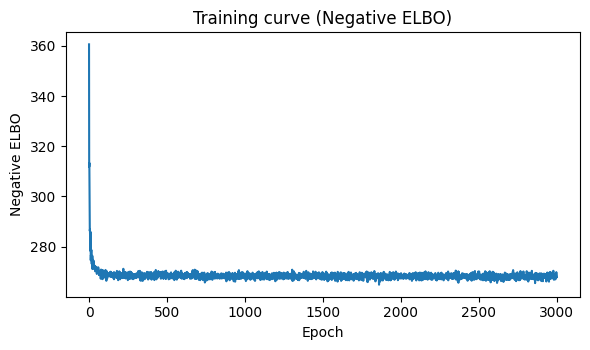

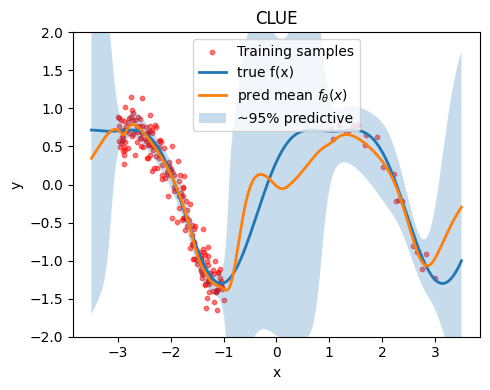

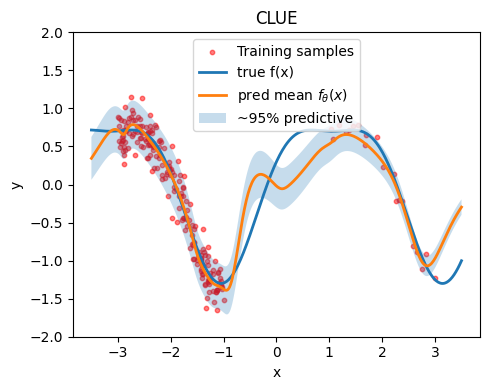

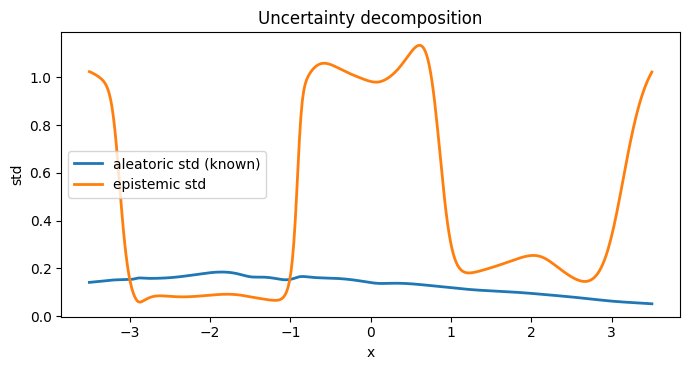

In [ ]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm

# ----------------------------
# Repro & device
# ----------------------------
torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda")  # or "cuda"

# ============================================================
# 1. Synthetic data (your setup)
# ============================================================
def f_np(x):
    return np.sin(1.5 * x) + 0.3 * np.cos(3.0 * x)

SIGMA_1 = 0.2
SIGMA_2 = 0.2
SIGMA_3 = 0.1
SIGMA_4 = 0.1
N_TRAIN_1, N_TRAIN_2, N_TRAIN_3, N_TRAIN_4, N_TEST = 100, 10, 10, 100, 400

np.random.seed(0)
x_train_1 = np.sort(np.random.uniform(-3, -2, (N_TRAIN_1, 1)).astype(np.float32), axis=0)
x_train_2 = np.sort(np.random.uniform(-2, -1, (N_TRAIN_1, 1)).astype(np.float32), axis=0)
x_train_3 = np.sort(np.random.uniform(1, 2, (N_TRAIN_2, 1)).astype(np.float32), axis=0)
x_train_4 = np.sort(np.random.uniform(2, 3, (N_TRAIN_2, 1)).astype(np.float32), axis=0)

x_train = np.vstack([x_train_1, x_train_2, x_train_3, x_train_4])
x_train = np.sort(x_train, axis=0)

# y_clean = f_np(x_train).astype(np.float32)
# y_train = (y_clean + np.random.normal(0.0, SIGMA, size=y_clean.shape)).astype(np.float32)
y_clean_1 = f_np(x_train_1).astype(np.float32)
y_clean_2 = f_np(x_train_2).astype(np.float32)
y_clean_3 = f_np(x_train_3).astype(np.float32)
y_clean_4 = f_np(x_train_4).astype(np.float32)
y_train_1 = (y_clean_1 + np.random.normal(0.0, SIGMA_1, size=y_clean_1.shape)).astype(np.float32)
y_train_2 = (y_clean_2 + np.random.normal(0.0, SIGMA_2, size=y_clean_2.shape)).astype(np.float32)
y_train_3 = (y_clean_3 + np.random.normal(0.0, SIGMA_3, size=y_clean_3.shape)).astype(np.float32)
y_train_4 = (y_clean_4 + np.random.normal(0.0, SIGMA_4, size=y_clean_3.shape)).astype(np.float32)
y_train = np.vstack([y_train_1, y_train_2, y_train_3, y_train_4])

x_test = np.linspace(-3.5, 3.5, N_TEST, dtype=np.float32).reshape(-1, 1)
y_test_clean = f_np(x_test).astype(np.float32)

X_train = torch.from_numpy(x_train).to(device)
Y_train = torch.from_numpy(y_train).squeeze(-1).to(device)      # [N]
X = torch.from_numpy(x_train).to(device)           # (N,1)
Y = torch.from_numpy(y_train).to(device)           # (N,1)
X_test = torch.from_numpy(x_test).to(device)
Xtest = torch.from_numpy(x_test).to(device)        # (Ntest,1)
Yclean_test = torch.from_numpy(y_test_clean).to(device)
Y_test_clean = torch.from_numpy(y_test_clean).squeeze(-1).to(device)

N = X_train.size(0)

# ----------------------------
# Prior Distribution
# ----------------------------
mu_mean_prior = 0
mu_std_prior = 1

logsigma_mean_prior = 0
logsigma_std_prior = 1

v0 = torch.tensor(mu_std_prior)
m0 = torch.tensor(mu_mean_prior)
v1 = torch.tensor(logsigma_std_prior)
m1 = torch.tensor(logsigma_mean_prior)

# ----------------------------
# Number of Samples
# ----------------------------
N_SAMPLES = 500  #J in original draft

# ----------------------------
# Model: MLP -> mean_1(x), var_1(x), mean_2(x), var_2(x)
# q(f, \sigma|x) = N(mean(x), var(x)), N(mean(x), var(x))
# ----------------------------
class EvidentialNet(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 4)  # outputs: [mean, raw_var]
        )

    def forward(self, x):
        out = self.net(x)
        mean_1 = out[:, :1]                      # (B,1)
        raw_var_1 = out[:, 1:2]                  # (B,1)
        var_1 = torch.nn.functional.softplus(raw_var_1) + 1e-6
        mean_2 = out[:, 2:3]                     # (B,1)
        raw_var_2 = out[:, 3:4]                  # (B,1)
        var_2 = torch.nn.functional.softplus(raw_var_2) + 1e-6
        # mean_2 = -1.89 * torch.ones_like(mean_1)
        # var_2 = 0.0001 * torch.ones_like(mean_1)
        return mean_1, var_1, mean_2, var_2

model = EvidentialNet(hidden=512).to(device)

# ----------------------------
# RBF correlation between anchor x and data x_n
# ----------------------------
ell_mu = 0.1  # lengthscale
ell_logsigma = 5

def rbf_rho(xq, Xtrain, ell):
    """
    xq:      (K,1)   query / anchor inputs
    Xtrain:  (B,1)   training batch inputs
    returns: (K,B)   rho_ij = exp(-||xq_i - Xtrain_j||^2 / (2 ell^2))
    """
    diff = xq - Xtrain.T         # (K,B)
    rho = torch.exp(-0.5 * (diff**2) / (ell**2))
    return rho

# ----------------------------
# OOD sampler for anchors
# ----------------------------
def sample_ood_x(x, n_anchors, device="cpu"):
    """
    Sample x.
    """
    # indices = torch.randint(low=0, high=x.shape[0], size=(n_anchors,))

    # # Select elements
    # choices = x[indices]
    choices = x
    return choices + torch.randn_like(choices) * 1

# ----------------------------
# Batching helper
# ----------------------------
def batches(X, Y, batch_size):
    N = X.shape[0]
    idx = torch.randperm(N)
    for i in range(0, N, batch_size):
        j = idx[i:i+batch_size]
        yield X[j], Y[j]

# ----------------------------
# ELBO per minibatch, with OOD anchors
# See Eq 5 in the paper
# For each OOD anchor x_a:
#   ELBO(x_a) = sum_{i in batch} E_q(z|x_a)[log p(y_i | z, x_a, x_i)]
#               - KL(q(z|x_a) || p(z))
# We approximate dataset sum by (N/B)*sum_{i in batch},
# and expectation over x_a by average over sampled anchors.
# ----------------------------
def elbo_ood_batch(model, xb, yb, n_anchors):
    """
    xb, yb: ID minibatch (B,1)
    n_anchors: number of OOD anchors sampled this step
    """
    B = xb.shape[0]

    # 1) Sample anchors x_a
    X_ood = sample_ood_x(xb, n_anchors, device=xb.device)   # (K,1)
    K = X_ood.shape[0]

    # 2) Posterior q(mu, sigma|x_a) for anchors
    mean_a, var_a, mean_b, var_b = model(X_ood)                        # (K,1)
    m_a = mean_a                            # (K,1)
    v_a = var_a                             # (K,1)
    m_b = mean_b                            # (K,1)
    v_b = var_b                             # (K,1)
    # 3) Sample mu, logsigma from q(mu, logsigma|x_a) for anchors
    m_a_sample = m_a + torch.randn_like(m_a) * torch.sqrt(v_a) #(K, 1)
    m_b_sample = m_b + torch.randn_like(m_b) * torch.sqrt(v_b) #(K, 1)

    # 4) Pairwise correlations between anchors and batch points
    rho_mu = rbf_rho(X_ood, xb, ell_mu)                       # (K,B)
    rho_sigma = rbf_rho(X_ood, xb, ell_logsigma)                 # (K,B)
    # 5) Sample mu_i|mu and sigma_i|sigma for data
    mu_i_mu = torch.div(rho_mu, v0) * m_a_sample
    mu_i_sigma2 = v0 - torch.div(rho_mu**2, v0)
    logsigma_i_mu = torch.div(rho_sigma, v1) * m_b_sample
    logsigma_i_sigma2 = v1 - torch.div(rho_sigma**2, v1) #(K,B)
    mu_samples = mu_i_mu.unsqueeze(-1) + torch.randn_like(mu_i_mu.unsqueeze(-1).repeat(1, 1, N_SAMPLES)) * torch.sqrt(mu_i_sigma2).unsqueeze(-1)# (K, B, N_SAMPLES)
    logsigma_samples = logsigma_i_mu.unsqueeze(-1) + torch.randn_like(logsigma_i_mu.unsqueeze(-1).repeat(1, 1, N_SAMPLES)) * torch.sqrt(logsigma_i_sigma2).unsqueeze(-1)# (K, B, N_SAMPLES)

    # 6) Expected log-likelihood term over q(z|x_a)
    Yb_vec = yb.squeeze(-1)                             # (B,)
    Yb_exp = Yb_vec.unsqueeze(0).unsqueeze(-1)                        # (1,B) -> (K,B, N_SAMPLES)
    log_sigma = logsigma_samples               # (K,B,S)
    inv_var = torch.exp(-2.0 * log_sigma)      # 1/sigma^2
    sq = (Yb_exp - mu_samples) ** 2                 # (K,B,S)
    logp = -0.5 * math.log(2.0 * math.pi) - log_sigma - 0.5 * sq * inv_var  # (K,B,S)
    log_mix = torch.log(torch.mean(torch.exp(logp), dim=-1) + 1e-6)   # (K,B)

    # If you want summed over batch:
    log_mix_sumB = log_mix.sum(dim=-1)                      # (K,)

    # Sum over batch points and anchors, scale by N/B (dataset size correction) and 1/K
    data_term = (N / B) * (log_mix_sumB.sum() / (K))

    # 5) KL term: average over anchors, independent prior p(f) = N(m0, v0)
    v0_t = torch.tensor(v0, dtype=torch.float32, device=xb.device)
    m0_t = torch.tensor(m0, dtype=torch.float32, device=xb.device)
    kl_each_mu = 0.5 * (
        (v_a + (m_a - m0_t)**2) / v0_t - 1.0 + torch.log(v0_t) - torch.log(v_a)
    )  # (K,)
    kl_term_mu = 1 * kl_each_mu.mean()

    v1_t = torch.tensor(v1, dtype=torch.float32, device=xb.device)
    m1_t = torch.tensor(m1, dtype=torch.float32, device=xb.device)
    kl_each_sigma = 0.5 * (
        (v_b + (m_b - m1_t)**2) / v1_t - 1.0 + torch.log(v1_t) - torch.log(v_b)
    )
    kl_term_sigma = 1 * kl_each_sigma.mean()

    elbo_batch = data_term - kl_term_mu - kl_term_sigma
    return elbo_batch, X_ood  # return anchors if you want to inspect them

# ----------------------------
# Training loop: TRAIN ON OOD ANCHORS
# ----------------------------
BATCH_SIZE = 220
N_ANCHORS = 220
EPOCHS = 3000

# optimizer = optim.SGD(model.parameters(), lr=2e-3)
# optimizer = torch.optim.SGD(model.parameters(), lr=2e-3)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_hist = []

for ep in tqdm(range(1, EPOCHS + 1)):
    model.train()
    total, nb = 0.0, 0
    for xb, yb in batches(X, Y, BATCH_SIZE):
        optimizer.zero_grad()
        elbo_b, X_ood_b = elbo_ood_batch(model, xb, yb, N_ANCHORS)
        loss = -elbo_b
        loss.backward()
        optimizer.step()
        total += loss.item()
        nb += 1
        # print("loss", loss.item())
    loss_hist.append(total / max(nb, 1))

# ----------------------------
# Evaluation
# ----------------------------
model.eval()
with torch.no_grad():
    mean_a, var_a, mean_b, var_b = model(Xtest)  # (N_test,1)
    aleatoric = mean_b + var_b/2  #Lognormal mean
    epistemic = var_a
    pred_var = epistemic
    pred_std = torch.sqrt(pred_var)


# ----------------------------
# Plots
# ----------------------------
plt.figure(figsize=(6.0,3.6))
plt.plot(loss_hist)
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO")
plt.title("Training curve (Negative ELBO)")
plt.tight_layout()
plt.show()


plt.figure(figsize=(5, 4))
plt.scatter(X.cpu().numpy(), Y.cpu().numpy(), s=10, alpha=0.5, color="r",  label="Training samples")
plt.plot(Xtest.cpu().numpy(), Yclean_test.cpu().numpy(), linewidth=2, label="true f(x)")
plt.plot(Xtest.cpu().numpy(), mean_a.cpu().numpy(), linewidth=2, label="pred mean " + r"$f_\theta(x)$")
upper = (mean_a + 2.0 * pred_std).cpu().numpy()
lower = (mean_a - 2.0 * pred_std).cpu().numpy()
plt.fill_between(Xtest.cpu().numpy().squeeze(), lower.squeeze(), upper.squeeze(),
                 alpha=0.25, label="~95% predictive")
plt.xlabel("x")
plt.ylabel("y")
plt.title("CLUE")
plt.legend()
plt.ylim(-2, 2)
plt.tight_layout()
plt.savefig("epi_cedr_toy_heter.pdf")
plt.show()


plt.figure(figsize=(5, 4))
plt.scatter(X.cpu().numpy(), Y.cpu().numpy(), s=10, alpha=0.5, color="r", label="Training samples")
plt.plot(Xtest.cpu().numpy(), Yclean_test.cpu().numpy(), linewidth=2, label="true f(x)")
plt.plot(Xtest.cpu().numpy(), mean_a.cpu().numpy(), linewidth=2, label="pred mean " + r"$f_\theta(x)$")
upper = (mean_a + 2.0 * torch.exp(aleatoric)).cpu().numpy()
lower = (mean_a - 2.0 * torch.exp(aleatoric)).cpu().numpy()
plt.fill_between(Xtest.cpu().numpy().squeeze(), lower.squeeze(), upper.squeeze(),
                 alpha=0.25, label="~95% predictive")
plt.xlabel("x")
plt.ylabel("y")
plt.title("CLUE")
plt.legend()
plt.ylim(-2, 2)
plt.tight_layout()
plt.savefig("alea_cedr_toy_heter.pdf")
plt.show()


plt.figure(figsize=(7.0,3.8))
plt.plot(Xtest.cpu().numpy(), torch.exp(aleatoric).cpu().numpy(), linewidth=2, label="aleatoric std (known)")
plt.plot(Xtest.cpu().numpy(), torch.sqrt(epistemic).cpu().numpy(), linewidth=2, label="epistemic std")
plt.xlabel("x")
plt.ylabel("std")
plt.title("Uncertainty decomposition")
plt.legend()
plt.tight_layout()

plt.show()

# KNOWN HOMOSCEDASTIC NOISE.

100%|██████████| 1000/1000 [00:08<00:00, 112.66it/s]


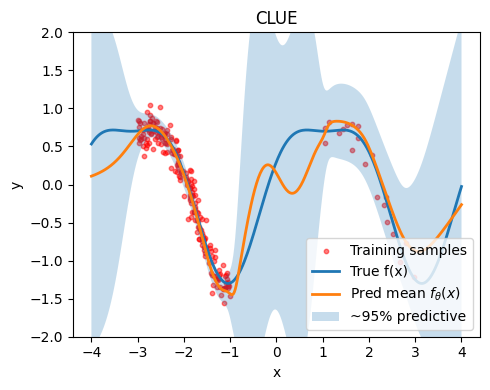

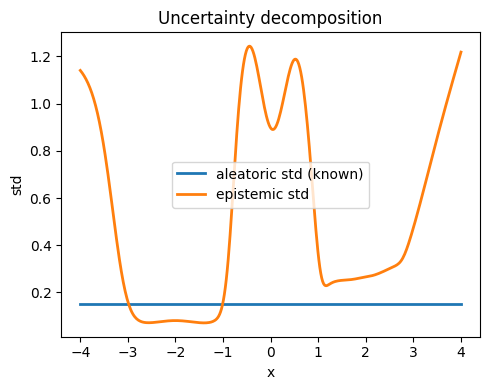

In [ ]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm

# ----------------------------
# Repro & device
# ----------------------------
torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cpu")  # or "cuda"

# ----------------------------
# Synthetic data (ID)
# ----------------------------
# def f_np(x):
#     return np.sin(1.5 * x) + 0.3 * np.cos(3.0 * x)
def f_np(x):
    sca = 1
    return np.sin(sca * 1.5 * x) + 0.3 * np.cos(sca * 3.0 * x)

SIGMA = 0.15                     # known noise std
SIGMA2 = float(SIGMA**2)

N_TRAIN_1, N_TRAIN_2, N_TEST = 200, 20, 400
np.random.seed(0)
x_train_1 = np.sort(np.random.uniform(-3, -1, (N_TRAIN_1, 1)).astype(np.float32), axis=0)
x_train_2 = np.sort(np.random.uniform(1, 3, (N_TRAIN_2, 1)).astype(np.float32), axis=0)
x_train = np.vstack([x_train_1, x_train_2])
x_train = np.sort(x_train, axis=0)
y_clean = f_np(x_train).astype(np.float32)
y_train = (y_clean + np.random.normal(0.0, SIGMA, size=y_clean.shape)).astype(np.float32)

x_test = np.linspace(-4, 4, N_TEST, dtype=np.float32).reshape(-1, 1)
y_test_clean = f_np(x_test).astype(np.float32)

X = torch.from_numpy(x_train).to(device)           # (N,1)
Y = torch.from_numpy(y_train).to(device)           # (N,1)
Xtest = torch.from_numpy(x_test).to(device)        # (Ntest,1)
Yclean_test = torch.from_numpy(y_test_clean).to(device)
N = X.shape[0]

# ----------------------------
# Prior over latent f(x)
# ----------------------------
m0 = 0.0          # prior mean for f
v0 = 1.0          # prior variance for f
sigma_f2 = v0     # notation match
sigma2_t = torch.tensor(SIGMA2, dtype=torch.float32, device=device)

# ----------------------------
# Model: MLP -> mean(x), var(x)
# q(f|x) = N(mean(x), var(x))
# ----------------------------
class EvidentialNet(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 2)  # outputs: [mean, raw_var]
        )

    def forward(self, x):
        out = self.net(x)
        mean = out[:, :1]                      # (B,1)
        raw_var = out[:, 1:2]                  # (B,1)
        var = torch.nn.functional.softplus(raw_var) + 1e-6
        return mean, var

model = EvidentialNet(hidden=256).to(device)

# ----------------------------
# RBF correlation between anchor x and data x_n
# ----------------------------
ell = 0.1  # lengthscale

def rbf_rho(xq, Xtrain, ell):
    """
    xq:      (K,1)   query / anchor inputs
    Xtrain:  (B,1)   training batch inputs
    returns: (K,B)   rho_ij = exp(-||xq_i - Xtrain_j||^2 / (2 ell^2))
    """
    diff = xq - Xtrain.T         # (K,B)
    rho = torch.exp(-0.5 * (diff**2) / (ell**2))
    return rho


# # ----------------------------
# # Matern correlation between anchor x and data x_n
# # ----------------------------
# nu = 0.5
# def matern_rho(xq, Xtrain, ell, nu):
#     """
#     xq:      (K,1)   query / anchor inputs
#     Xtrain:  (B,1)   training batch inputs
#     returns: (K,B)   rho_ij = exp(-||xq_i - Xtrain_j||^2 / (2 ell^2))
#     """
#     diff = xq - Xtrain.T         # (K,B)
#     rho = (1.0 + diff / ell)**(-nu)
#     return rho


# ----------------------------
# OOD sampler for anchors
# ----------------------------
# def sample_ood_x(n, ood_range=OOD_RANGE, id_range=ID_RANGE, device="cpu"):
#     """
#     Sample x outside the ID interval [id_range[0], id_range[1]]
#     from a larger outer interval ood_range.
#     """
#     n1 = n // 2
#     n2 = n - n1
#     lo1, hi1 = ood_range[0], id_range[0]  # far left
#     lo2, hi2 = id_range[1], ood_range[1]  # far right
#     x_left = np.random.uniform(lo1, hi1, size=(n1, 1)).astype(np.float32)
#     x_right = np.random.uniform(lo2, hi2, size=(n2, 1)).astype(np.float32)
#     x = np.vstack([x_left, x_right])
#     np.random.shuffle(x)
#     return torch.from_numpy(x).to(device)

def sample_ood_x(x, device="cpu"):
    """
    Sample x.
    """

    return x + torch.randn_like(x) * 1

# ----------------------------
# Batching helper
# ----------------------------
def batches(X, Y, batch_size):
    N = X.shape[0]
    idx = torch.randperm(N)
    for i in range(0, N, batch_size):
        j = idx[i:i+batch_size]
        yield X[j], Y[j]

# ----------------------------
# ELBO per minibatch, with OOD anchors
#
# For each OOD anchor x_a:
#   ELBO(x_a) = sum_{i in batch} E_q(f|x_a)[log p(y_i | f, x_a, x_i)]
#               - KL(q(f|x_a) || p(f))
# We approximate dataset sum by (N/B)*sum_{i in batch},
# and expectation over x_a by average over sampled anchors.
# ----------------------------
def elbo_ood_batch(model, xb, yb, n_anchors):
    """
    xb, yb: ID minibatch (B,1)
    n_anchors: number of OOD anchors sampled this step
    """
    B = xb.shape[0]

    # 1) Sample OOD anchors x_a
    # X_ood = sample_ood_x(n_anchors, device=xb.device)   # (K,1)
    X_ood = sample_ood_x(xb, device=xb.device)   # (K,1)
    K = X_ood.shape[0]

    # 2) Posterior q(f|x_a) for anchors
    mean_a, var_a = model(X_ood)                        # (K,1)
    m_a = mean_a.squeeze(-1)                            # (K,)
    v_a = var_a.squeeze(-1)                             # (K,)

    # 3) Pairwise correlations between anchors and batch points
    rho = rbf_rho(X_ood, xb, ell)                       # (K,B)
    tau2 = sigma_f2 * (1.0 - rho**2)                    # (K,B)
    var_y = tau2 + SIGMA2                               # (K,B)  variance of y_i | f, x_a, x_i

    # 4) Expected log-likelihood term over q(f|x_a)
    #    E_q[(y_i - rho f)^2] = (y_i - rho m)^2 + rho^2 v
    Yb_vec = yb.squeeze(-1)                             # (B,)
    Yb_exp = Yb_vec.unsqueeze(0)                        # (1,B) -> (K,B)
    m_a_exp = m_a.unsqueeze(1)                          # (K,1) -> (K,B)
    v_a_exp = v_a.unsqueeze(1)                          # (K,1) -> (K,B)

    resid2 = (Yb_exp - rho * m_a_exp)**2 + (rho**2) * v_a_exp  # (K,B)

    loglik = -0.5 * torch.log(2 * math.pi * var_y) - 0.5 * resid2 / var_y  # (K,B)

    # Sum over batch points and anchors, scale by N/B (dataset size correction) and 1/K
    data_term = (N / B) * (loglik.sum() / K)

    # 5) KL term: average over anchors, independent prior p(f) = N(m0, v0)
    v0_t = torch.tensor(v0, dtype=torch.float32, device=xb.device)
    m0_t = torch.tensor(m0, dtype=torch.float32, device=xb.device)
    kl_each = 0.5 * (
        (v_a + (m_a - m0_t)**2) / v0_t - 1.0 + torch.log(v0_t) - torch.log(v_a)
    )  # (K,)
    kl_term = kl_each.mean()

    elbo_batch = data_term - kl_term
    return elbo_batch, X_ood  # return anchors if you want to inspect them

# ----------------------------
# Training loop: TRAIN ON OOD ANCHORS
# ----------------------------
BATCH_SIZE = 220
N_ANCHORS = 220
EPOCHS = 1000

optimizer = optim.Adam(model.parameters(), lr=1e-2)
# optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay = 1e-2)
loss_hist = []

for ep in tqdm(range(1, EPOCHS + 1)):
    model.train()
    total, nb = 0.0, 0
    for xb, yb in batches(X, Y, BATCH_SIZE):
        optimizer.zero_grad()
        elbo_b, X_ood_b = elbo_ood_batch(model, xb, yb, N_ANCHORS)
        loss = -elbo_b
        loss.backward()
        optimizer.step()
        total += loss.item()
        nb += 1
    loss_hist.append(total / max(nb, 1))
    # if ep % 100 == 0:
    #     print(f"Epoch {ep:04d} | ELBO (batch avg): {(-loss_hist[-1]):.3f}")

# ----------------------------
# Evaluation
# ----------------------------
model.eval()
with torch.no_grad():
    gamma_g, v_g = model(Xtest)  # (N_test,1)
    # Predictive variance decomposition:
    aleatoric = sigma2_t.expand_as(gamma_g)
    epistemic = v_g.expand_as(gamma_g)
    pred_var = epistemic
    pred_std = torch.sqrt(pred_var)

# ----------------------------
# Plots
# ----------------------------
plt.figure(figsize=(5, 4))
plt.scatter(X.cpu().numpy(), Y.cpu().numpy(), s=10, alpha=0.5, color="r",  label="Training samples")
plt.plot(Xtest.cpu().numpy(), Yclean_test.cpu().numpy(), linewidth=2, label="True f(x)")
plt.plot(Xtest.cpu().numpy(), gamma_g.cpu().numpy(), linewidth=2, label="Pred mean " + r"$f_\theta(x)$")
upper = (gamma_g + 2.0 * pred_std).cpu().numpy()
lower = (gamma_g - 2.0 * pred_std).cpu().numpy()
plt.fill_between(Xtest.cpu().numpy().squeeze(), lower.squeeze(), upper.squeeze(),
                 alpha=0.25, label="~95% predictive")
plt.xlabel("x")
plt.ylabel("y")
plt.title("CLUE")
plt.legend()
plt.ylim(-2, 2)
plt.tight_layout()
plt.savefig("epi_cedr_toy_homo.pdf")
plt.show()

plt.figure(figsize=(5, 4))
plt.plot(Xtest.cpu().numpy(), torch.sqrt(aleatoric).cpu().numpy(), linewidth=2, label="aleatoric std (known)")
plt.plot(Xtest.cpu().numpy(), torch.sqrt(epistemic).cpu().numpy(), linewidth=2, label="epistemic std")
plt.xlabel("x")
plt.ylabel("std")
plt.title("Uncertainty decomposition")
plt.legend()
plt.tight_layout()

plt.show()

# Binary Classification

<>:241: SyntaxWarning: invalid escape sequence '\s'
<>:241: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-1352214292.py:241: SyntaxWarning: invalid escape sequence '\s'
  plt.plot(Xtest.cpu().numpy(), pred.cpu().numpy(), linewidth=2, label="Mean $\sigma_{Link}(z)$")


Train: torch.Size([220, 1]) torch.Size([220, 1]) Test: torch.Size([400, 1])
Label mean: 0.4681817889213562


100%|██████████| 3000/3000 [00:41<00:00, 72.23it/s]


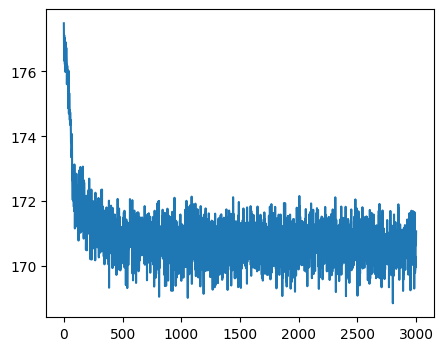

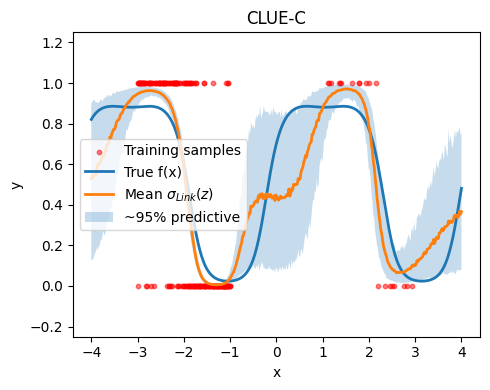

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm

# ----------------------------
# Repro & device
# ----------------------------
torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda")  # or "cuda"

# ----------------------------
# Latent function (score/logit)
# ----------------------------
def f_np(x, sca=1.0):
    return np.sin(sca * 1.5 * x) + 0.3 * np.cos(sca * 3.0 * x)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# ----------------------------
# Binary dataset with a gap
# ----------------------------
def make_binary_gap_dataset(
    n_left=200,
    n_right=20,
    n_test=400,
    left_range=(-3.0, -1.0),
    right_range=(1.0, 3.0),
    test_range=(-4.0, 4.0),
    sca=1.0,
    temperature=0.35,   # smaller -> more separable
    seed=0,
):
    rng = np.random.default_rng(seed)

    x_left = np.sort(rng.uniform(left_range[0], left_range[1], (n_left, 1)).astype(np.float32), axis=0)
    x_right = np.sort(rng.uniform(right_range[0], right_range[1], (n_right, 1)).astype(np.float32), axis=0)
    x_train = np.sort(np.vstack([x_left, x_right]), axis=0)

    # latent logits
    logits = f_np(x_train, sca=sca).astype(np.float32) / np.float32(temperature)
    p = sigmoid(logits).astype(np.float32)                 # (N,1) in (0,1)
    y = rng.binomial(1, p).astype(np.float32)              # sampled labels {0,1}

    # test grid (use clean prob/labels for evaluation/plots)
    x_test = np.linspace(test_range[0], test_range[1], n_test, dtype=np.float32).reshape(-1, 1)
    logits_test = f_np(x_test, sca=sca).astype(np.float32) / np.float32(temperature)
    p_test = sigmoid(logits_test).astype(np.float32)

    # Torch tensors
    X = torch.from_numpy(x_train).to(device)               # (N,1)
    Y = torch.from_numpy(y).to(device)                     # (N,1) float 0/1 (good for BCEWithLogitsLoss if you keep logits)
    Xtest = torch.from_numpy(x_test).to(device)            # (Ntest,1)
    Ptest = torch.from_numpy(p_test).to(device)            # (Ntest,1) "clean" probabilities

    return X, Y, Xtest, Ptest

X, Y, Xtest, Ptest = make_binary_gap_dataset()
print("Train:", X.shape, Y.shape, "Test:", Xtest.shape)
print("Label mean:", Y.mean().item())
N = X.shape[0]
# ----------------------------
# Prior over latent f(x)
# ----------------------------
m0 = 0.0          # prior mean for f
v0 = 1          # prior variance for f
# sigma_f2 = v0     # notation match
# sigma2_t = torch.tensor(SIGMA2, dtype=torch.float32, device=device)

# ----------------------------
# Model: MLP -> mean(x), var(x)
# q(f|x) = N(mean(x), var(x))
# ----------------------------
class EvidentialNet(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 2)  # outputs: [mean, raw_var]
        )

    def forward(self, x):
        out = self.net(x)
        mean = out[:, :1]                      # (B,1)
        raw_var = out[:, 1:2]                  # (B,1)
        var = torch.nn.functional.softplus(raw_var) + 1e-6
        return mean, var

model = EvidentialNet(hidden=256).to(device)

# ----------------------------
# RBF correlation between anchor x and data x_n
# ----------------------------
ell = 0.1  # lengthscale
N_SAMPLES = 500

def rbf_rho(xq, Xtrain, ell):
    """
    xq:      (K,1)   query / anchor inputs
    Xtrain:  (B,1)   training batch inputs
    returns: (K,B)   rho_ij = exp(-||xq_i - Xtrain_j||^2 / (2 ell^2))
    """
    diff = xq - Xtrain.T         # (K,B)
    rho = torch.exp(-0.5 * (diff**2) / (ell**2))
    return rho

def sample_ood_x(x, n_anchors, device="cpu"):
    """
    Sample x.
    """
    indices = torch.randint(low=0, high=x.shape[0], size=(n_anchors,))

    # # Select elements
    choices = x[indices]
    # choices = x
    return choices + torch.randn_like(choices) * 1

# ----------------------------
# Batching helper
# ----------------------------
def batches(X, Y, batch_size):
    N = X.shape[0]
    idx = torch.randperm(N)
    for i in range(0, N, batch_size):
        j = idx[i:i+batch_size]
        yield X[j], Y[j]


# ----------------------------
# ELBO per minibatch, with OOD anchors
# See Eq 5 in the paper
# For each OOD anchor x_a:
#   ELBO(x_a) = sum_{i in batch} E_q(z|x_a)[log p(y_i | z, x_a, x_i)]
#               - KL(q(z|x_a) || p(z))
# We approximate dataset sum by (N/B)*sum_{i in batch},
# and expectation over x_a by average over sampled anchors.
# ----------------------------
def elbo_ood_batch(model, xb, yb, n_anchors, BCELoss):
    """
    xb, yb: ID minibatch (B,1)
    n_anchors: number of OOD anchors sampled this step
    """

    B = xb.shape[0]

    # 1) Sample anchors x_a
    X_ood = sample_ood_x(xb, n_anchors, device=xb.device)   # (K,1)
    K = X_ood.shape[0]

    # 2) Posterior q(mu, sigma|x_a) for anchors
    mean_a, var_a = model(X_ood)                        # (K,1)
    m_a = mean_a                            # (K,1)
    v_a = var_a                             # (K,1)
    # 3) Sample mu, logsigma from q(mu, logsigma|x_a) for anchors
    m_a_sample = m_a + torch.randn_like(m_a) * torch.sqrt(v_a) #(K, 1)

    # 4) Pairwise correlations between anchors and batch points
    rho_mu = rbf_rho(X_ood, xb, ell)                       # (K,B)
    # 5) Sample mu_i|mu and sigma_i|sigma for data
    mu_i_mu = torch.div(rho_mu, v0) * m_a_sample
    mu_i_sigma2 = v0 - torch.div(rho_mu**2, v0)
    mu_samples = mu_i_mu.unsqueeze(-1) + torch.randn_like(mu_i_mu.unsqueeze(-1).repeat(1, 1, N_SAMPLES)) * torch.sqrt(mu_i_sigma2).unsqueeze(-1)# (K, B, N_SAMPLES)

    # 6) Expected log-likelihood term over q(z|x_a)
    Yb_vec = yb.squeeze(-1)                             # (B,)
    Yb_vec = Yb_vec.unsqueeze(0).unsqueeze(-1).repeat(n_anchors, 1, N_SAMPLES)
    # print(mu_samples.shape)
    # print(Yb_vec)
    data_term = - (N / B) * BCELoss(mu_samples, Yb_vec) / (K * N_SAMPLES)

    # 5) KL term: average over anchors, independent prior p(f) = N(m0, v0)
    v0_t = torch.tensor(v0, dtype=torch.float32, device=xb.device)
    m0_t = torch.tensor(m0, dtype=torch.float32, device=xb.device)
    kl_each_mu = 0.5 * (
        (v_a + (m_a - m0_t)**2) / v0_t - 1.0 + torch.log(v0_t) - torch.log(v_a)
    )  # (K,)
    kl_term_mu = 0.1 * kl_each_mu.mean()

    elbo_batch = data_term - kl_term_mu
    # print(data_term)
    # print(kl_term_mu)
    return elbo_batch, X_ood  # return anchors if you want to inspect them

# ----------------------------
# Training loop: TRAIN ON OOD ANCHORS
# ----------------------------
BATCH_SIZE = 220
N_ANCHORS = 220
EPOCHS = 3000

optimizer = optim.Adam(model.parameters(), lr=1e-4)
# optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay = 1e-2)
loss_hist = []

BCELoss = nn.BCEWithLogitsLoss(reduction = 'sum')
link = nn.Sigmoid()
for ep in tqdm(range(1, EPOCHS + 1)):
    model.train()
    total, nb = 0.0, 0
    for xb, yb in batches(X, Y, BATCH_SIZE):
        optimizer.zero_grad()
        elbo_b, X_ood_b = elbo_ood_batch(model, xb, yb, N_ANCHORS, BCELoss)
        loss = -elbo_b
        loss.backward()
        optimizer.step()
        total += loss.item()
        nb += 1
    loss_hist.append(total / max(nb, 1))
    # if ep % 100 == 0:
    #     print(f"Epoch {ep:04d} | ELBO (batch avg): {(-loss_hist[-1]):.3f}")

# ----------------------------
# Evaluation
# ----------------------------
model.eval()
with torch.no_grad():
    m_a, v_a = model(Xtest)  # (N_test,1)
    m_a_samples = m_a + torch.randn_like(m_a.repeat(1, N_SAMPLES)) * torch.sqrt(v_a) #(K, 1)
    # Predictive variance decomposition:
    pred = torch.mean(link(m_a_samples), dim = -1)
    up = np.quantile(link(m_a_samples).cpu().numpy(), 0.975, axis = 1)
    low = np.quantile(link(m_a_samples).cpu().numpy(), 0.025, axis = 1)
# # ----------------------------
# # Plots
# # ----------------------------
plt.figure(figsize=(5, 4))
plt.plot(loss_hist)

plt.figure(figsize=(5, 4))
plt.scatter(X.cpu().numpy(), Y.cpu().numpy(), s=10, alpha=0.5, color="r",  label="Training samples")
plt.plot(Xtest.cpu().numpy(), Ptest.cpu().numpy(), linewidth=2, label="True f(x)")
plt.plot(Xtest.cpu().numpy(), pred.cpu().numpy(), linewidth=2, label="Mean $\sigma_{Link}(z)$")
upper = (up)
lower = (low)
plt.fill_between(Xtest.cpu().numpy().squeeze(), lower.squeeze(), upper.squeeze(),
                 alpha=0.25, label="~95% predictive")
plt.xlabel("x")
plt.ylabel("y")
plt.title("CLUE-C")
plt.legend()
plt.ylim(-0.25, 1.25)
plt.tight_layout()
plt.savefig("epi_cedr_binary_classifier.pdf")
plt.show()

